# L2 — Formulation du problème d'apprentissage

**Objectif.** Dire précisément ce qu'on prédit, pourquoi c'est un problème de gestion de slices B5G, quelles
hypothèses on teste, et fixer un protocole d'évaluation qui ne se laisse pas tromper par la fuite de données.

## 1. La tâche

**Entrée** : une configuration réseau candidate = topologie + capacités des liens + routage + slices admises
(type, facteur de provisionnement δ, réservations WFQ) + trafic.
**Sortie** : pour chaque flux, son **délai moyen** (cible principale). Gigue et pertes sont des cibles secondaires.

**Pourquoi un problème de gestion de slices.** Un orchestrateur qui veut admettre une nouvelle slice URLLC ou
changer un routage doit savoir « est-ce que toutes les slices respecteront encore leur SLA ? ». Le simulateur
paquet par paquet répond en **10,8 h en moyenne** par scénario (médiane 9,4 h, `sim_wallclock_s` de
`results/eda_summary.json`). Un modèle appris répond en millisecondes : c'est un *modèle de performance
« what-if »*, la motivation des auteurs du jeu et des modèles RouteNet / GNNetSlice.

**Pourquoi log10(délai).** Le délai couvre 8,3 ordres de grandeur (1e-5 s à ~1 900 s), asymétrie 38 en brut
contre 0,99 en log10 (figure `L1_03`). Une erreur en log10 est une erreur **relative** : se tromper d'un facteur 10
coûte pareil à 1 ms ou à 10 s.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS_DIR, PROCESSED_DIR
from src.eda import fig_leakage, fig_splits
from src.plotting import set_style, savefig

set_style()
eda = json.load(open(RESULTS_DIR / "eda_summary.json", encoding="utf-8"))
sim_h = pd.read_parquet(PROCESSED_DIR / "scenarios.parquet", columns=["sim_wallclock_s"]).sim_wallclock_s / 3600
print(f"temps de simulation par scénario : moyenne {sim_h.mean():.1f} h, médiane {sim_h.median():.1f} h, min {sim_h.min():.2f} h")
print("asymétrie du délai : brut", round(eda["delay_global"]["skew_raw"], 1), "| log10", round(eda["delay_global"]["skew_log10"], 2))

temps de simulation par scénario : moyenne 10.8 h, médiane 9.4 h, min 0.06 h
asymétrie du délai : brut 38.3 | log10 0.99


## 2. Hypothèses (tranchées en L6)

- **H1** — Un GNN qui voit les liens et files partagés entre flux bat un modèle plat avec les mêmes entrées,
  surtout à forte charge (ρ ≥ 1).
- **H2** — Tous les modèles se dégradent sur les *événements* (congestion, famine), les modèles plats davantage.
- **H3** — Le GNN généralise mieux à des topologies inédites.
- **H4** — (issue de L1) Les flux *affamés* (part WFQ quasi nulle sur un lien saturé) sont là où les modèles
  plats échouent le plus : la règle à seuil seule a beaucoup de faux positifs (77 158 flux rapides la remplissent).

## 3. Protocole : pourquoi l'unité de découpage est le **scénario**

Les flux d'un même scénario partagent des liens et des files : leurs entrées et leurs délais sont fortement
corrélés. Si on tire les flux au hasard, le test contient des « frères » de flux d'entraînement, et le modèle
peut mémoriser le scénario au lieu d'apprendre la physique du réseau. **On le prouve** :

- même modèle (LightGBM, paramètres fixes non réglés), mêmes variables, mêmes 1 500 scénarios tirés au hasard
  (hors topologies inédites), 3 graines ;
- 20 % des scénarios sont mis de côté comme **E = scénarios vraiment nouveaux**, jamais vus par aucun schéma ;
- schéma **A** : split aléatoire des flux 80/20 ; schéma **B** : split des scénarios 80/20 ;
- on compare l'erreur **estimée** (sur le test du schéma) à l'erreur **réelle** (sur E).

In [2]:
res = pd.read_csv(RESULTS_DIR / "leakage_experiment.csv")
tab = (res.groupby(["scheme", "kind"])[["mae_log", "mse_log"]].agg(["mean", "std"]).round(4))
print(tab.to_string())
print("\npart des flux de test dont le scénario est aussi dans le train :")
print(res.groupby("scheme").frac_test_flows_in_seen_scenario.mean().round(3).to_dict())

                           mae_log         mse_log        
                              mean     std    mean     std
scheme           kind                                     
A_flow_split     estimated  0.1267  0.0051  0.0675  0.0058
                 true       0.3987  0.0126  0.4777  0.0762
B_scenario_split estimated  0.3584  0.0239  0.3916  0.0640
                 true       0.4102  0.0165  0.5163  0.0719

part des flux de test dont le scénario est aussi dans le train :
{'A_flow_split': 1.0, 'B_scenario_split': 0.0}


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


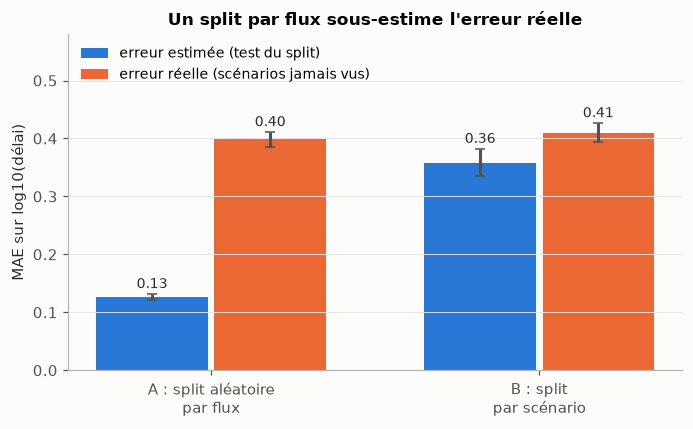

In [3]:
fig = fig_leakage(res); savefig(fig, "L2_01_fuite"); plt.show()

In [4]:
g = res.groupby(["scheme", "kind"]).mae_log.mean()
gap_a = g[("A_flow_split", "true")] / g[("A_flow_split", "estimated")]
gap_b = g[("B_scenario_split", "true")] / g[("B_scenario_split", "estimated")]
summary = {"mae_log": {f"{s}|{k}": float(v) for (s, k), v in g.items()},
           "optimism_factor_A_true_over_estimated": float(gap_a),
           "optimism_factor_B_true_over_estimated": float(gap_b)}
json.dump(summary, open(RESULTS_DIR / "leakage_summary.json", "w"), indent=1)
print(f"facteur d'optimisme : A = {gap_a:.2f}×, B = {gap_b:.2f}×")

facteur d'optimisme : A = 3.15×, B = 1.14×


**Lecture.** Avec le split par flux (A), 100 % des flux de test ont des « frères » dans l'entraînement et l'erreur
annoncée est environ **3 fois trop faible** par rapport à l'erreur réelle. Avec le split par scénario (B), aucun
flux de test n'a de frère et l'estimation est proche de la réalité. Le petit écart restant pour B vient de la
variance entre scénarios (écart-type entre graines du même ordre), pas d'une fuite.

## 4. Les découpages gelés

1. **Topologies inédites d'abord** : 15 % des topologies, tirées dans chaque quartile de taille du cœur
   (S ≤ 13, M ≤ 21, L ≤ 33, XL > 33 nœuds) → toutes leurs scénarios forment `test_unseen_topo`.
2. **Reste des scénarios** : 70/15/15 groupés par scénario, stratifiés par tercile de ρ max (les scénarios
   congestionnés sont dans les trois splits en même proportion).
3. Tout ajustement (scaler, encodeur, seuil) se fait sur `train` ; les hyperparamètres sur `val` ; `test`
   n'est regardé qu'une fois.

In [5]:
splits = pd.read_parquet(PROCESSED_DIR / "splits.parquet")
ss = json.load(open(RESULTS_DIR / "splits_summary.json", encoding="utf-8"))
print(pd.DataFrame({"scénarios": ss["n_scenarios"], "topologies": ss["n_topologies"],
                    "ρ max médian": ss["scen_rho_max_median"], "nœuds cœur médian": ss["core_nodes_median"]}).to_string())
print("\nflux par split et par slice :")
fl = pd.DataFrame(ss["n_flows_by_slice"]).T
print(fl.to_string())

                  scénarios  topologies  ρ max médian  nœuds cœur médian
train                  4233         137         1.633               16.0
val                     907         127         1.609               16.0
test                    907         134         1.650               16.0
test_unseen_topo       1080          24         1.350               16.0

flux par split et par slice :
                   URLLC   eMBB    mMTC
train             190814  39026  704707
val                41387   8398  160081
test               42169   8630  151154
test_unseen_topo   51086   9952  169265


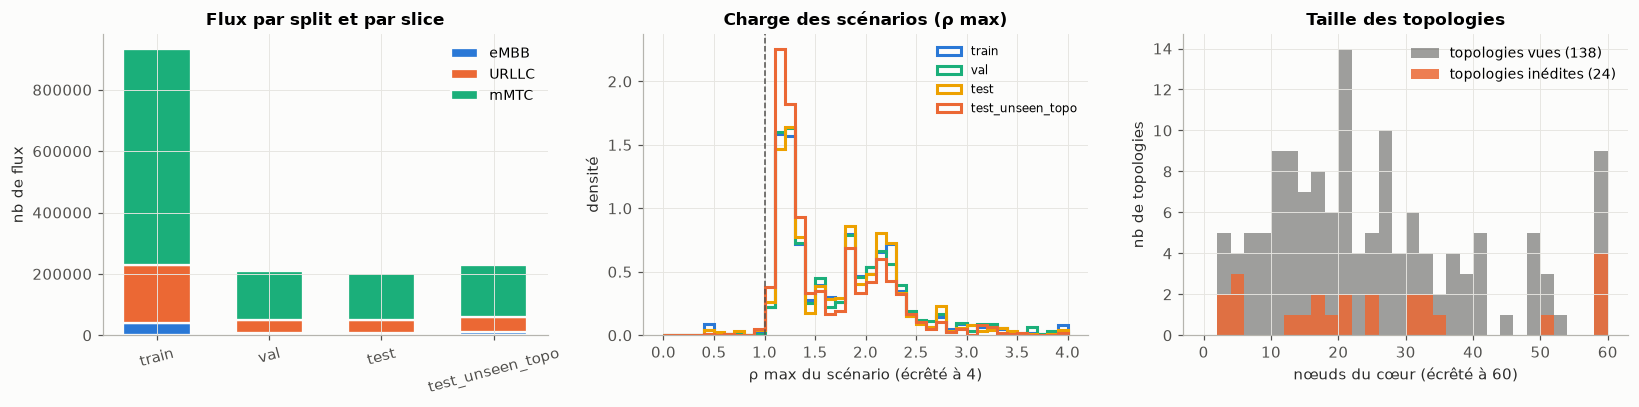

In [6]:
fig = fig_splits(splits, fl); savefig(fig, "L2_02_splits"); plt.show()

**Attention (à garder pour H3).** Les topologies inédites sont en moyenne **moins chargées** (ρ max médian 1,35
contre 1,63 en train). Si un modèle est meilleur ou moins bon sur `test_unseen_topo`, on ne saura pas dire si c'est
la topologie nouvelle ou la charge différente. En L6, on compare donc aussi **à charge égale**
(par tranche de ρ max) pour séparer les deux effets.